# Topic: Student Dropout Analysis

### Name: Muhammad Adam Harith bin Mohd Zaki
### Matrics No: 23002459

## Dataset
**Source:** Kaggle (https://www.kaggle.com/datasets/meharshanali/student-dropout-prediction-dataset)

**Size:** 10000 records and 19 attributes

## Business Understanding
#### Problem Statements
* High student dropout rates lead to lost academic potential and financial instability for both the university and the student.
* It is difficult to manually identify students at risk of dropping out due to the financial, academic and personal factors.

#### Objectives
* To analyze student data to identify the key factors that most strongly influence a student's decision to drop out.
* To explore the relationship between academic performance, stress factors, financial and behavorial data.

#### Potential Impacts
* **Educational Institutions:** Can optimize their support resources and improve their overall graduation rates.
* **Students:** Individuals at risk can receive proactive support to help them complete their degrees.
* **Policy Makers:** Can use the trends identified to design better student welfare programs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('student_dropout_dataset_v3.csv')

In [2]:
df.head(10)

,Student_ID,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout
0,1,22.1,Male,25000.0,Yes,3.36,86.1,2,20.4,Yes,No,5.5,0.96,0.90,0.90,Year 1,Arts,High School,0
1,2,20.7,Male,25000.0,Yes,4.30,68.0,2,44.0,No,No,6.8,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1
2,3,22.4,Male,40183.0,Yes,4.40,70.9,0,48.9,Yes,No,5.5,1.68,1.32,1.32,Year 1,Arts,Master,0
3,4,24.4,Male,NaN,Yes,NaN,82.2,2,38.6,No,No,NaN,1.78,1.77,1.77,Year 1,CS,High School,1
4,5,20.5,Female,25319.0,Yes,4.19,75.7,1,23.0,No,No,7.0,1.48,0.91,0.87,Year 4,Business,Bachelor,0
5,6,20.5,Male,25000.0,Yes,4.11,89.1,2,47.1,No,Yes,6.0,2.52,2.72,2.69,Year 3,Business,NaN,0
6,7,24.5,Male,25000.0,Yes,3.00,78.2,1,37.4,Yes,Yes,7.3,0.64,0.33,0.44,Year 4,CS,Bachelor,0
7,8,22.7,Female,25000.0,Yes,2.12,86.4,1,34.0,No,Yes,6.5,1.79,1.14,1.14,Year 1,Arts,High School,0
8,9,20.0,Male,57413.0,Yes,4.07,97.5,3,52.1,No,No,4.2,3.08,2.81,2.81,Year 1,CS,High School,0
9,10,22.2,Female,44930.0,Yes,2.98,82.2,1,19.7,No,No,6.7,1.59,1.73,1.73,Year 1,Science,Master,0


## Data Understanding

### Dataset Description

In [3]:
num_records, num_attributes = df.shape
print(f"Number of records: {num_records}")
print(f"Number of attributes: {num_attributes}")
print("\nAttribute Types:")
print(df.dtypes)

Number of records: 10000
Number of attributes: 19

Attribute Types:
Student_ID                 int64
Age                      float64
Gender                    object
Family_Income            float64
Internet_Access           object
Study_Hours_per_Day      float64
Attendance_Rate          float64
Assignment_Delay_Days      int64
Travel_Time_Minutes      float64
Part_Time_Job             object
Scholarship               object
Stress_Index             float64
GPA                      float64
Semester_GPA             float64
CGPA                     float64
Semester                  object
Department                object
Parental_Education        object
Dropout                    int64
dtype: object


**Target variable:**
* Dropout (0 = retained, 1 = dropped out)

**Key Features:**
* Student_ID: Unique student identifier
* Age: Student age in years
* Gender: Male / Female
* Family_Income: Monthly family income
* Internet_Access: Yes / No
* Study_Hours_per_Day: Average study hours per day
* Attendance_Rate: Percentage of attendance
* Assignment_Delay_Days: Average assignment delay in days
* Travel_Time_Minutes: Daily commute in minutes
* Part_Time_Job: Yes / No
* Scholarship: Yes / No
* Stress_Index: Self-reported stress level (1–10)
* GPA, Semester_GPA, CGPA: Academic performance
* Semester: Current year (Year 1–4)
* Department: Science, Arts, Business, CS, Engineering
* Parental_Education: Highest education of parents

### Summary Statistics

In [4]:
# Numerical
display(df.describe())

,Student_ID,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA,Dropout
count,10000.00000,10000.00000,9500.000000,9500.000000,10000.00000,10000.000000,10000.00000,9500.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,21.02606,38377.247474,4.014592,81.73683,1.799700,30.17926,5.507147,2.308440,2.300057,2.298761,0.23540
std,2886.89568,2.13981,20496.232179,1.295450,8.22093,1.344307,11.91887,1.765951,1.061717,1.074407,1.072555,0.42427
min,1.00000,17.00000,25000.000000,0.500000,38.20000,0.000000,5.00000,1.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,19.50000,25000.000000,3.160000,76.40000,1.000000,21.90000,4.300000,1.550000,1.520000,1.520000,0.00000
50%,5000.50000,21.00000,29740.500000,4.000000,81.80000,2.000000,30.20000,5.500000,2.350000,2.350000,2.350000,0.00000
75%,7500.25000,22.50000,44520.000000,4.870000,87.30000,3.000000,38.40000,6.700000,3.120000,3.150000,3.150000,0.00000
max,10000.00000,29.60000,316601.000000,8.980000,100.00000,8.000000,74.90000,10.000000,4.000000,4.000000,4.000000,1.00000


In [5]:
# Categorical
display(df.describe(include=['object']))

,Gender,Internet_Access,Part_Time_Job,Scholarship,Semester,Department,Parental_Education
count,10000,10000,10000,10000,10000,10000,9489
unique,2,2,2,2,4,5,4
top,Female,Yes,No,No,Year 4,Science,Bachelor
freq,5011,8769,5996,6489,2536,2061,3949


### Initial Observations

In [6]:
dropout_counts = df['Dropout'].value_counts(normalize=True) * 100
print(f"Dropout Rate in Dataset: {dropout_counts[1]:.2f}%")

Dropout Rate in Dataset: 23.54%


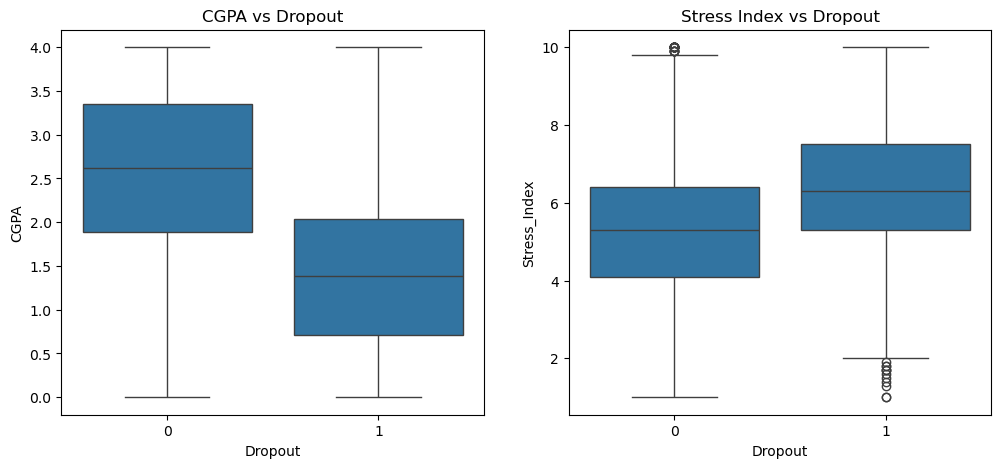

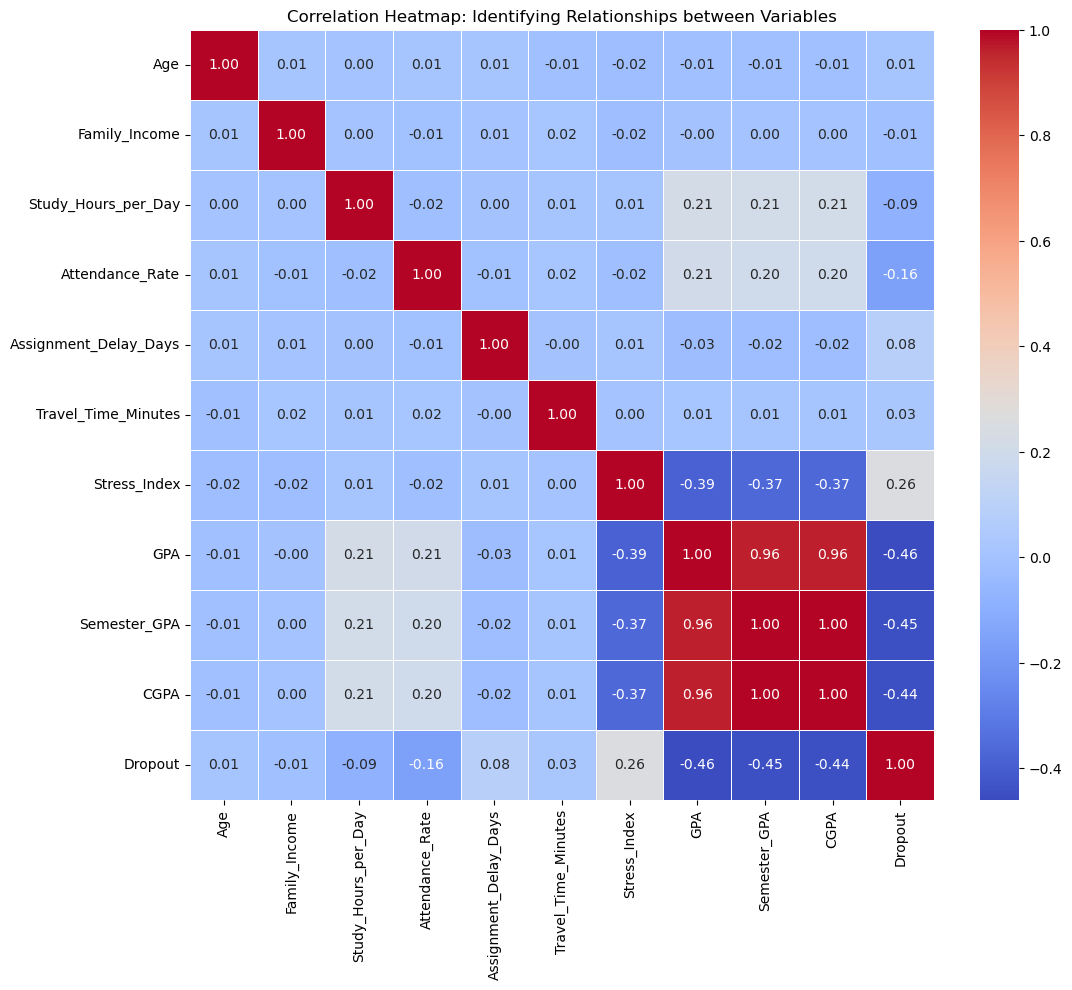

In [7]:
plt.figure(figsize=(12, 5))

# CGPA vs Dropout
plt.subplot(1, 2, 1)
sns.boxplot(x='Dropout', y='CGPA', data=df)
plt.title('CGPA vs Dropout')

# Stress Index vs Dropout
plt.subplot(1, 2, 2)
sns.boxplot(x='Dropout', y= 'Stress_Index', data=df)
plt.title('Stress Index vs Dropout')

#Correlation Heatmap
numeric_df = df.select_dtypes(include=['float64', 'int64']).drop(columns=['Student_ID'])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap: Identifying Relationships between Variables')
plt.show()

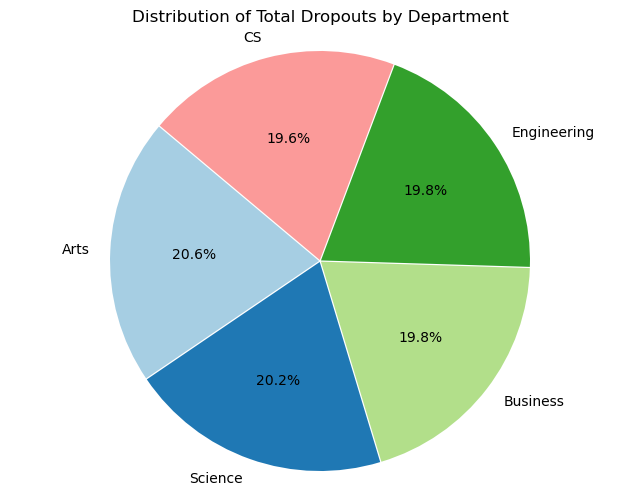

In [8]:
dropped_out = df[df['Dropout'] == 1]
dept_counts = dropped_out['Department'].value_counts()

plt.figure(figsize=(8, 6))
plt.pie(dept_counts, 
        labels=dept_counts.index, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=plt.cm.Paired.colors,
        explode=[0.005] * len(dept_counts))

plt.title('Distribution of Total Dropouts by Department')
plt.axis('equal') 
plt.show()

In [9]:
def get_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return len(outliers), lower_bound, upper_bound

for col in ['Family_Income', 'Attendance_Rate', 'Stress_Index', 'Study_Hours_per_Day']:
    count, low, high = get_outliers(df, col)

    if col == 'Family_Income':
        low = max(0, low)
        count = len(df[(df[col] < low) | (df[col] > high)])

    print(f"{col}: Found {count} outliers (Values outside {low:.2f} to {high:.2f})")

Family_Income: Found 604 outliers (Values outside 0.00 to 73800.00)
Attendance_Rate: Found 57 outliers (Values outside 60.05 to 103.65)
Stress_Index: Found 0 outliers (Values outside 0.70 to 10.30)
Study_Hours_per_Day: Found 86 outliers (Values outside 0.60 to 7.44)


## Data Preprocessing

### Handling Missing Values

In [10]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0])
print(f"Duplicates: {df.duplicated().sum()}")

Missing values per column:
Family_Income          500
Study_Hours_per_Day    500
Stress_Index           500
Parental_Education     511
dtype: int64
Duplicates: 0


In [11]:
df_cleaned = df.drop(columns=['Student_ID'])

In [12]:
df_cleaned['Family_Income'] = df_cleaned['Family_Income'].fillna(df_cleaned['Family_Income'].median())
df_cleaned['Study_Hours_per_Day'] = df_cleaned['Study_Hours_per_Day'].fillna(df_cleaned['Study_Hours_per_Day'].median())
df_cleaned['Stress_Index'] = df_cleaned['Stress_Index'].fillna(df_cleaned['Stress_Index'].median())
df_cleaned['Parental_Education'] = df_cleaned['Parental_Education'].fillna(df_cleaned['Parental_Education'].mode()[0])

### Handling Noise or Outliers

In [13]:
Q1 = df_cleaned['Family_Income'].quantile(0.25)
Q3 = df_cleaned['Family_Income'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
df_cleaned['Family_Income'] = np.where(df_cleaned['Family_Income'] > upper_limit, upper_limit, df_cleaned['Family_Income'])

### Data Transformation

In [14]:
binary_cols = ['Internet_Access', 'Part_Time_Job', 'Scholarship']
for col in binary_cols:
    df_cleaned[col] = df_cleaned[col].map({'Yes': 1, 'No': 0})

df_cleaned['Gender'] = df_cleaned['Gender'].map({'Male': 1, 'Female': 0})

# One-Hot Encoding for Department, Semester and Parental_Education
df_cleaned = pd.get_dummies(df_cleaned, columns=['Department', 'Semester', 'Parental_Education'], drop_first=True)

In [15]:
scaler = StandardScaler()
num_cols = ['Age', 'Family_Income', 'Study_Hours_per_Day', 'Attendance_Rate', 
            'Assignment_Delay_Days', 'Travel_Time_Minutes', 'Stress_Index', 
            'GPA', 'Semester_GPA', 'CGPA']
df_cleaned[num_cols] = scaler.fit_transform(df_cleaned[num_cols])

## Summary

**Key Findings**
* **Academic Performance:** GPA and CGPA are the strongest predictors. As grades go up, dropout rates drop significantly.
* **Campus Engagement:** Low attendance is a minor factor.
* **Mental Well-being:** This analysis suggests that high stress levels and assignment delays are linked to students leaving.
* **Uniform Risk:** Dropout rates are consistent across all departments, meaning this is a campus-wide issue.

**Preprocessing Actions and Justifications**
* Irrelevant Data: Removed column. Random label with no predictive value.
* Missing Data: Used median for numbers and mode for categorical value. Fills the gap without letting outliers disturb the average.
* Outliers: Capped high-value column using IQR method. It prevents outliers from skewing the results.
* Encoding: Turned text into numbers, because models only able to understand mathematical value.
* Scaling: Used StandardScaler to normalize ranges to ensure a uniform scale, preventing bias.

**Conclusion**
* This analysis proves that a combination of academic struggle and low attendance drives student dropout. By focusing on Attendance and CGPA, the university can identify at-risk students early. This processed dataset is now ready for predictive modeling to help improve student retention.